# **Mice Protein Expression: data audit**

> **Question: do the profiles of the 77 proteins distinguish the eight experimental groups in mice not seen before?**

This notebook audits the data and describes its structure. Its main finding is that the 15 measurements of each animal are close to replicates, which leads to the two choices used in `02_classification.ipynb`: splitting and evaluating by animal, and summarizing each animal by its mean protein profile.

1. Data audit
2. Within- and between-animal variability
3. Per-animal profiles and PCA
4. Box plots by class
5. Trisomic mice: PCA and K-means

## **1. Data audit**

### **1.1 Imports**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

### **1.2 Data ingestion**

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
mice_protein_expression = fetch_ucirepo(id=342)

# data (as pandas dataframes)
X = mice_protein_expression.data.features
y = mice_protein_expression.data.targets

### **1.3 Metadata and variables**

In [3]:
# metadata
print(mice_protein_expression.metadata)

# variable information
print(mice_protein_expression.variables)

{'uci_id': 342, 'name': 'Mice Protein Expression', 'repository_url': 'https://archive.ics.uci.edu/dataset/342/mice+protein+expression', 'data_url': 'https://archive.ics.uci.edu/static/public/342/data.csv', 'abstract': 'Expression levels of 77 proteins measured in the cerebral cortex of 8 classes of control and Down syndrome mice exposed to context fear conditioning, a task used to assess associative learning.', 'area': 'Biology', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 1080, 'num_features': 80, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': ['MouseID'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2015, 'last_updated': 'Tue Apr 16 2024', 'dataset_doi': '10.24432/C50S3Z', 'creators': ['Clara Higuera', 'Katheleen Gardiner', 'Krzysztof Cios'], 'intro_paper': {'ID': 475, 'type': 'NATIVE', 'title': 'Self-Organizing Feature Maps Identify Proteins Critical

### **1.4 Features (`X`) and target (`y`)**

In [4]:
X.head()

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior
0,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,1.750936,...,0.106305,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S
1,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,1.596377,...,0.106592,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S
2,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,1.561316,...,0.108303,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S
3,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,1.595086,...,0.103184,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S
4,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,1.504230,...,0.104784,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S


In [5]:
y.head()

,class
0,c-CS-m
1,c-CS-m
2,c-CS-m
3,c-CS-m
4,c-CS-m


### **1.5 Full table (`df_full`)**

Features of `X`, target of `y` and the `MouseID` identifier.

In [6]:
df_full = mice_protein_expression.data.original
df_full.shape

(1080, 82)

In [7]:
df_full.head()

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


### **1.6 Number of classes**

In [8]:
df_full["class"].nunique()

8

### **1.7 Missing values per column**

In [9]:
missings = df_full.isna().sum()

has_missing_values = missings > 0
missings = missings[has_missing_values].sort_values(ascending=False)
missings

BCL2_N        285
H3MeK4_N      270
BAD_N         213
EGR1_N        210
H3AcK18_N     180
pCFOS_N        75
ELK_N          18
Bcatenin_N     18
MEK_N           7
ITSN1_N         3
BDNF_N          3
NR1_N           3
NR2A_N          3
pAKT_N          3
pBRAF_N         3
pCAMKII_N       3
DYRK1A_N        3
pNR2B_N         3
pNR2A_N         3
pNR1_N          3
pMEK_N          3
PKCA_N          3
pJNK_N          3
pERK_N          3
pELK_N          3
pCREB_N         3
CREB_N          3
ERK_N           3
pPKCAB_N        3
BRAF_N          3
CAMKII_N        3
AKT_N           3
pRSK_N          3
SOD1_N          3
APP_N           3
RSK_N           3
TRKA_N          3
GSK3B_N         3
JNK_N           3
MTOR_N          3
P38_N           3
RAPTOR_N        3
pNUMB_N         3
NR2B_N          3
AMPKA_N         3
DSCR1_N         3
pMTOR_N         3
TIAM1_N         3
pP70S6_N        3
dtype: int64

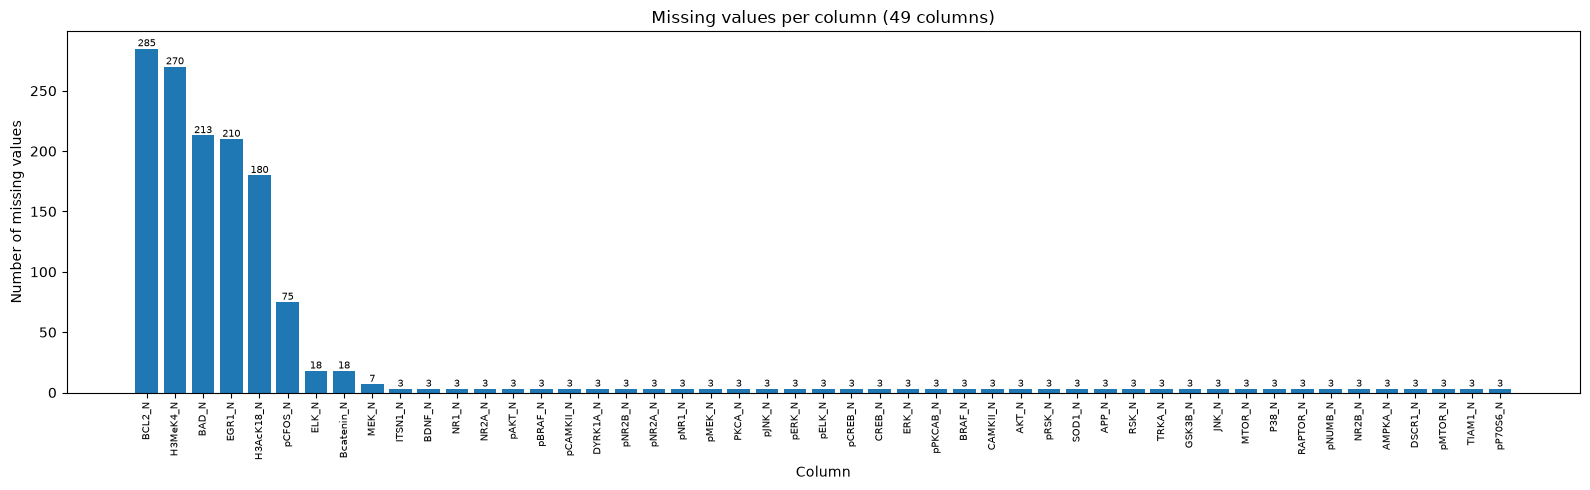

In [10]:
fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(missings.index, missings.values)
ax.bar_label(ax.containers[0], fontsize=7)
ax.set_title(f"Missing values per column ({len(missings)} columns)")
ax.set_xlabel("Column")
ax.set_ylabel("Number of missing values")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

Only protein columns have missing values. Six proteins (BCL2_N, H3MeK4_N, BAD_N, EGR1_N, H3AcK18_N, pCFOS_N) concentrate most of them; dozens of others have exactly 3.

### **1.8 `MouseID`: animal and measurement**

`MouseID` has the form `<animal>_<measurement>`.

In [11]:
df_full.MouseID

0          309_1
1          309_2
2          309_3
3          309_4
4          309_5
          ...   
1075    J3295_11
1076    J3295_12
1077    J3295_13
1078    J3295_14
1079    J3295_15
Name: MouseID, Length: 1080, dtype: str

In [12]:
df_parts = df_full["MouseID"].str.split("_", expand=True)
df_parts = df_parts.rename(columns={0: "animal_id", 1: "measurement"})
df_parts["measurement"] = pd.to_numeric(df_parts["measurement"], errors="raise")

print(f"Mice: {df_parts['animal_id'].nunique()}")
print("")
print(f"Protein measurements per mouse: {len(df_parts) // df_parts['animal_id'].nunique()}")
print("")
print(f"Number of duplicated MouseID: {df_full['MouseID'].duplicated().sum()}")

Mice: 72

Protein measurements per mouse: 15

Number of duplicated MouseID: 0


In [13]:
df_parts.groupby(["animal_id"], as_index=True).agg(measurements=("measurement","nunique"))

,measurements
animal_id,
18899,15
293,15
294,15
309,15
311,15
...,...
50810E,15
50810F,15
J1291,15


In [14]:
df = df_full.assign(animal_id=df_parts["animal_id"], measurement=df_parts["measurement"])

protein_cols = [c for c in df.columns if c.endswith("_N")]
meta_cols = ["Genotype", "Treatment", "Behavior", "class"]

### **1.9 The 15 measurements of one animal**

In [15]:
def mouse_view(animal_id):
    """15 measurements of one mouse: 77 proteins + genotype, treatment, behavior and class."""
    view = df[df["animal_id"] == str(animal_id)]
    return view.sort_values("measurement").set_index("measurement")[protein_cols + meta_cols]

mouse_view(309)

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
measurement,,,,,,,,,,,,,,,,,,,,,
1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,1.750936,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,1.596377,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,1.561316,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,1.595086,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,1.504230,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m
6,0.447506,0.628176,0.367388,2.385939,4.807635,0.218578,0.176233,2.141282,0.195188,1.442398,...,0.109446,0.439833,0.116657,0.140766,0.142180,1.816389,Control,Memantine,C/S,c-CS-m
7,0.428033,0.573696,0.342709,2.334224,4.473130,0.225173,0.184004,2.012414,0.195789,1.612036,...,0.111483,0.406293,0.137229,0.156682,0.157499,1.528484,Control,Memantine,C/S,c-CS-m
8,0.416923,0.564036,0.327703,2.260135,4.268735,0.214834,0.179668,2.007985,0.189803,1.424601,...,0.113080,0.382532,0.123376,0.155612,0.159409,1.652658,Control,Memantine,C/S,c-CS-m
9,0.386311,0.538428,0.317720,2.125725,4.063950,0.207222,0.167778,1.861514,0.180684,1.261891,...,0.105490,0.435687,0.125173,0.152711,0.158235,1.834599,Control,Memantine,C/S,c-CS-m


### **1.10 Are the metadata constant per animal?**

In [16]:
df.groupby("animal_id")[meta_cols].nunique().eq(1).all()

Genotype     True
Treatment    True
Behavior     True
class        True
dtype: bool

### **1.11 Animals per class**

72 animals, 7 to 10 per class. The experimental unit is the animal, not the measurement.

In [17]:
df.groupby(["class"]).agg(mice_per_class=("animal_id", "nunique")).sort_values(by="mice_per_class", ascending=False)

,mice_per_class
class,
c-CS-m,10
c-SC-m,10
c-CS-s,9
c-SC-s,9
t-CS-m,9
t-SC-m,9
t-SC-s,9
t-CS-s,7


### **1.12 Missing values per animal**

In [18]:
na_per_mouse = df[protein_cols].isna().groupby(df["animal_id"]).sum()
na_per_mouse[na_per_mouse.sum(axis=1) > 0].sum(axis=1).sort_values(ascending=False)

animal_id
3426      129
50810F     75
3479       64
322        60
3605       60
3424       60
3417       60
3418       60
3420       60
365        48
3419       45
294        45
3507       45
3416       45
3411       45
364        45
321        45
3414       30
18899      30
3484       30
J1291      30
3502       30
3477       30
3481       30
3534       30
309        15
311        15
320        15
3520       15
3517       15
3516       15
3513       15
3503       15
3498       15
J2292      15
J3295      15
dtype: int64

## **2. Within- and between-animal variability**

The 15 measurements of an animal include replicates and dilutions of the same sample, so the within-animal standard deviation mixes technical and preparation variation; it is not internal biological fluctuation.

### **2.1 Standard deviation of the 15 measurements of each animal, per protein**

In [19]:
std_summary = (
    df
    .groupby("animal_id", as_index=False)
    .agg(
        **{
            f"{protein}_std": (protein, "std")
            for protein in protein_cols
        }
    )
)

std_summary

,animal_id,DYRK1A_N_std,ITSN1_N_std,BDNF_N_std,NR1_N_std,NR2A_N_std,pAKT_N_std,pBRAF_N_std,pCAMKII_N_std,pCREB_N_std,...,SHH_N_std,BAD_N_std,BCL2_N_std,pS6_N_std,pCFOS_N_std,SYP_N_std,H3AcK18_N_std,EGR1_N_std,H3MeK4_N_std,CaNA_N_std
0,18899,0.060311,0.079883,0.025214,0.149617,0.631472,0.018544,0.016655,0.139336,0.019901,...,0.035588,0.027215,0.038517,0.010624,NaN,0.033650,0.039663,NaN,0.061908,0.052528
1,293,0.048618,0.063913,0.018658,0.189876,0.584687,0.014291,0.010139,0.411359,0.010969,...,0.008466,0.015279,0.019880,0.004656,0.011614,0.028122,0.030828,0.022933,0.017555,0.040187
2,294,0.019255,0.024501,0.026519,0.092259,0.391965,0.032467,0.035266,0.264655,0.016815,...,0.018426,NaN,NaN,0.003869,0.017344,0.020095,NaN,0.043438,0.052096,0.040223
3,309,0.053882,0.092236,0.037763,0.308802,0.921450,0.007469,0.009508,0.310471,0.019517,...,0.006266,0.028828,NaN,0.005046,0.009004,0.021881,0.021754,0.035751,0.034716,0.143946
4,311,0.087654,0.102818,0.033130,0.258626,1.008991,0.025306,0.017229,0.282546,0.011904,...,0.015598,0.025267,0.021238,0.013744,NaN,0.029646,0.018302,0.032461,0.035040,0.128465
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,50810E,0.078149,0.106174,0.037191,0.198175,0.443776,0.009442,0.013113,0.232562,0.014239,...,0.014723,0.019265,0.019671,0.007316,0.017865,0.064937,0.010511,0.021816,0.033611,0.078675
68,50810F,0.065035,0.064223,0.019536,0.149021,0.807416,0.022519,0.018077,0.284694,0.017241,...,0.018702,NaN,NaN,0.006514,0.022497,0.075461,NaN,NaN,NaN,0.047784
69,J1291,0.042144,0.066704,0.024412,0.159357,0.363939,0.076221,0.007318,0.364906,0.013860,...,0.014323,0.024374,NaN,0.003210,NaN,0.023875,0.013298,0.023860,0.023863,0.040776
70,J2292,0.020683,0.039280,0.021189,0.149888,0.431969,0.015741,0.016058,0.316468,0.008567,...,0.009793,0.015419,0.014062,0.004802,0.007899,0.037471,0.007012,0.018188,0.021430,0.076274


### **2.2 Mean of the 15 measurements of each animal, per protein**

In [20]:
mean_summary = (
    df
    .groupby("animal_id", as_index=False)
    .agg(
        **{
            f"{protein}_mean": (protein, "mean")
            for protein in protein_cols
        }
    )
)

mean_summary

,animal_id,DYRK1A_N_mean,ITSN1_N_mean,BDNF_N_mean,NR1_N_mean,NR2A_N_mean,pAKT_N_mean,pBRAF_N_mean,pCAMKII_N_mean,pCREB_N_mean,...,SHH_N_mean,BAD_N_mean,BCL2_N_mean,pS6_N_mean,pCFOS_N_mean,SYP_N_mean,H3AcK18_N_mean,EGR1_N_mean,H3MeK4_N_mean,CaNA_N_mean
0,18899,0.428381,0.617834,0.299208,2.053351,3.461564,0.281945,0.191150,2.541373,0.210844,...,0.236160,0.192990,0.179952,0.120311,NaN,0.424551,0.207383,NaN,0.264955,1.328343
1,293,0.268072,0.532736,0.293274,2.278292,3.466264,0.255595,0.193701,3.825613,0.240396,...,0.204713,0.139175,0.121962,0.134576,0.110451,0.494021,0.426291,0.170461,0.297441,1.257729
2,294,0.318000,0.486584,0.315980,2.479140,3.838981,0.261231,0.204978,5.130094,0.223610,...,0.272471,NaN,NaN,0.133939,0.137972,0.483603,NaN,0.236137,0.230726,1.058736
3,309,0.421063,0.576510,0.356447,2.278252,4.354744,0.219549,0.182195,1.922373,0.196064,...,0.192871,0.151524,NaN,0.101042,0.115433,0.423088,0.136374,0.169300,0.169590,1.674160
4,311,0.600591,0.678479,0.334548,2.277561,4.234706,0.227820,0.184262,1.931669,0.176511,...,0.188092,0.166315,0.168952,0.105205,NaN,0.426774,0.141512,0.201386,0.200284,1.193285
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,50810E,0.508742,0.748007,0.318928,2.299097,3.791904,0.209596,0.163295,2.570700,0.212496,...,0.231358,0.163582,0.134391,0.107420,0.133887,0.499405,0.183951,0.172079,0.211742,1.704720
68,50810F,0.439384,0.560736,0.331974,2.224129,3.968663,0.278213,0.206829,3.747682,0.258409,...,0.194244,NaN,NaN,0.108895,0.114522,0.366727,NaN,NaN,NaN,1.455950
69,J1291,0.241612,0.421927,0.291766,2.145327,2.954803,0.270469,0.186234,3.249092,0.246158,...,0.225712,0.163488,NaN,0.113939,NaN,0.334016,0.293926,0.160057,0.250398,1.355835
70,J2292,0.258354,0.402856,0.363226,2.336278,4.499927,0.238544,0.180765,5.258103,0.200197,...,0.239638,0.157116,0.129411,0.131622,0.125829,0.511127,0.208220,0.192311,0.194597,1.190845


### **2.3 Within/between ratio**

- `within`: for each protein, the standard deviation of the 15 measurements of each animal, averaged over the 72 animals.
- `between`: for each protein, the standard deviation of the 72 animal means.

A `within / between` ratio well below 1 means the measurements of an animal are close to each other compared with the differences between animals.

In [21]:
within = (
    std_summary
    .set_index("animal_id")
    .mean()
    .rename(index=lambda column: column.removesuffix("_std"))
    .rename("within")
)

between = (
    mean_summary
    .set_index("animal_id")
    .std()
    .rename(index=lambda column: column.removesuffix("_mean"))
    .rename("between")
)

In [22]:
variability_summary = (
    pd.concat([within, between], axis=1)
    .rename_axis("protein")
    .reset_index()
)

variability_summary

,protein,within,between
0,DYRK1A_N,0.059434,0.239865
1,ITSN1_N,0.085517,0.233322
2,BDNF_N,0.031132,0.037280
3,NR1_N,0.240097,0.245981
4,NR2A_N,0.676145,0.642533
...,...,...,...
72,SYP_N,0.032062,0.056948
73,H3AcK18_N,0.018912,0.056128
74,EGR1_N,0.026598,0.029630
75,H3MeK4_N,0.031264,0.045507


In [23]:
variability_summary["within_between_ratio"] = variability_summary["within"] / variability_summary["between"]

In [24]:
variability_summary.sort_values(by="within_between_ratio")

,protein,within,between,within_between_ratio
50,AcetylH3K9_N,0.022059,0.183460,0.120240
20,BRAF_N,0.036245,0.212934,0.170215
46,pPKCG_N,0.109718,0.567137,0.193459
32,SOD1_N,0.059917,0.270224,0.221731
0,DYRK1A_N,0.059434,0.239865,0.247780
...,...,...,...,...
44,P70S6_N,0.122566,0.115284,1.063167
68,BAD_N,0.021469,0.019319,1.111295
71,pCFOS_N,0.016917,0.015008,1.127257
31,Bcatenin_N,0.351226,0.260977,1.345811


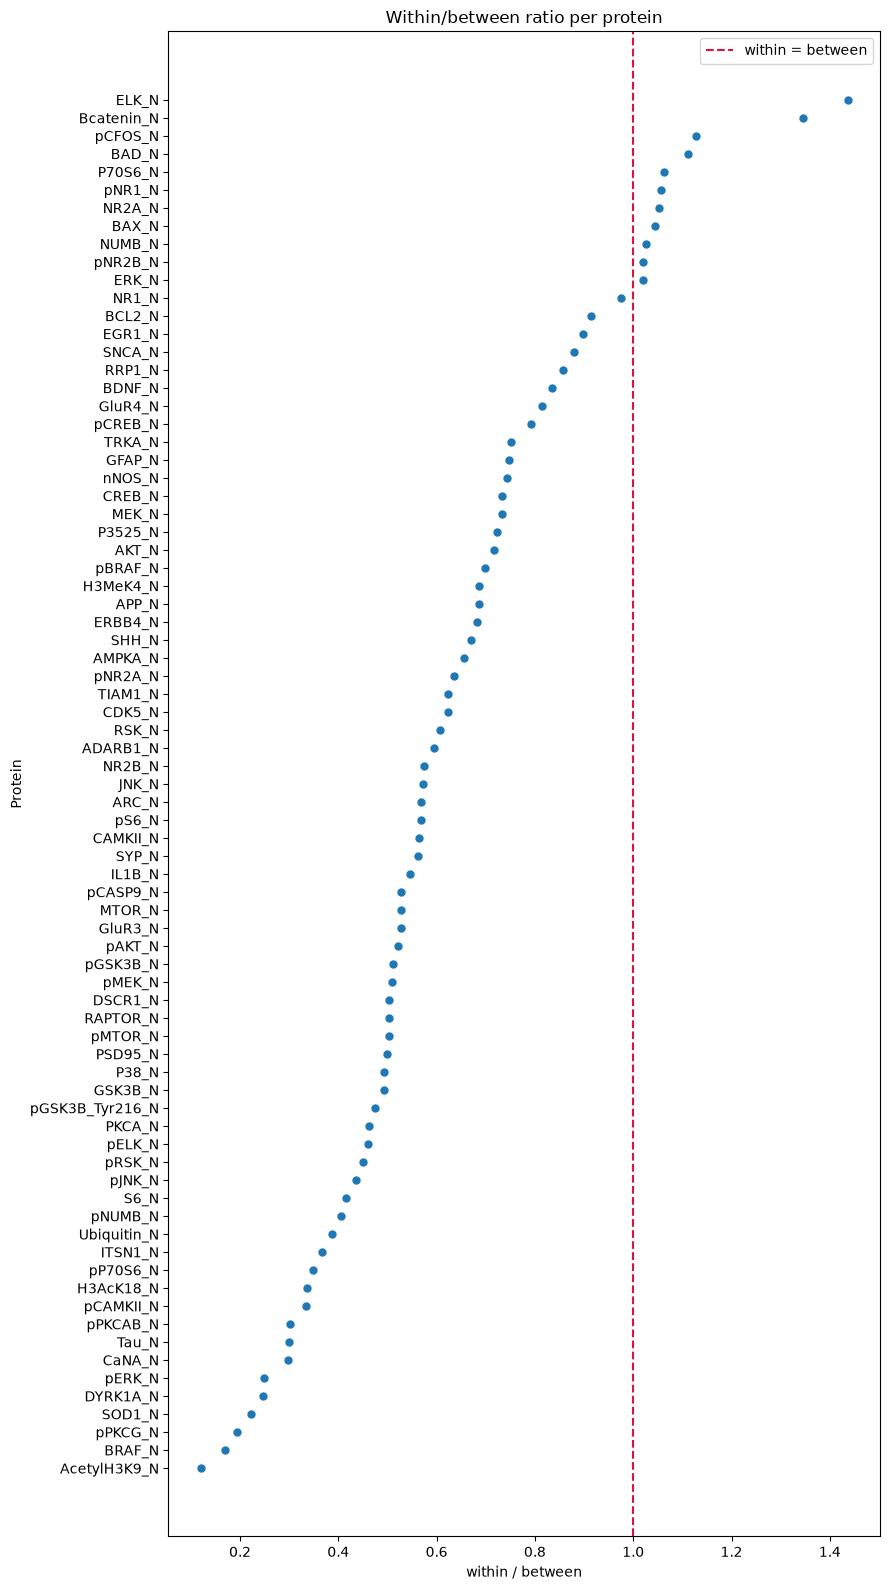

In [25]:
plot_df = variability_summary.sort_values("within_between_ratio")

fig, ax = plt.subplots(figsize=(9, 16))
ax.scatter(
    plot_df["within_between_ratio"],
    plot_df["protein"],
    s=25,
)
ax.axvline(1, color="crimson", linestyle="--", label="within = between")
ax.set_title("Within/between ratio per protein")
ax.set_xlabel("within / between")
ax.set_ylabel("Protein")
ax.legend()
plt.tight_layout()
plt.show()

For most proteins the variation within an animal is smaller than the variation between animals. The 15 rows of an animal are close to replicates, not 15 independent mice. Two consequences for the modeling:

- train and test (and cross-validation folds) must be split **by animal**;
- each animal can be summarized by the **mean of its 15 measurements**, giving a 72 × 77 matrix, compared in `02_classification.ipynb` with the original measurements.

## **3. Per-animal profiles and PCA**

From here on each animal is one row, in two separate tables: the mean and the standard deviation of the 15 measurements of each protein.

### **3.1 Per-animal tables: means and standard deviations**

In [26]:
animal_keys = ["animal_id"] + meta_cols

animal_mean_df = df.groupby(animal_keys, as_index=False)[protein_cols].mean()
animal_std_df = df.groupby(animal_keys, as_index=False)[protein_cols].std()

animal_mean_df.shape, animal_std_df.shape

((72, 82), (72, 82))

In [27]:
n_animals = df["animal_id"].nunique()

for name, table in [("animal_mean_df", animal_mean_df), ("animal_std_df", animal_std_df)]:
    assert len(table) == n_animals, f"{name}: {len(table)} rows for {n_animals} animals"
    assert table["animal_id"].is_unique, f"{name}: repeated animal_id"

labels_aligned = animal_mean_df[animal_keys].equals(animal_std_df[animal_keys])
print(f"One row per animal in both tables: {n_animals} animals")
print(f"Labels aligned row by row: {labels_aligned}")

One row per animal in both tables: 72 animals
Labels aligned row by row: True


In [28]:
missing_by_table = pd.DataFrame({
    "animal_mean_df": animal_mean_df[protein_cols].isna().sum(),
    "animal_std_df": animal_std_df[protein_cols].isna().sum(),
})

same_missing_cells = (
    animal_mean_df[protein_cols].isna().equals(animal_std_df[protein_cols].isna())
)

print(f"Missing values in animal_mean_df: {missing_by_table['animal_mean_df'].sum()}")
print(f"Missing values in animal_std_df: {missing_by_table['animal_std_df'].sum()}")
print(f"Same missing cells in both tables: {same_missing_cells}")

missing_by_table[missing_by_table.sum(axis=1) > 0].sort_values("animal_mean_df", ascending=False)

Missing values in animal_mean_df: 84
Missing values in animal_std_df: 84
Same missing cells in both tables: True


,animal_mean_df,animal_std_df
BCL2_N,19,19
H3MeK4_N,18,18
EGR1_N,14,14
BAD_N,14,14
H3AcK18_N,12,12
pCFOS_N,5,5
ELK_N,1,1
Bcatenin_N,1,1


Both tables have the same missing cells: when a protein is missing for an animal, it is missing in all of its 15 measurements. Partial cases, such as the 3 rows of animal 3426, disappear after aggregation.

### **3.2 PCA of the per-animal means**

The PCA uses only the 77 proteins: missing values are imputed with each protein's median and each protein is standardized. Genotype, Treatment, Behavior and class are used only to color the plots.

In [29]:
def fit_protein_pca(table):
    """PCA of the proteins of a per-animal table: median imputation, standardization and PCA."""
    pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA())
    components = pipeline.fit_transform(table[protein_cols])
    pca = pipeline[-1]

    pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
    scores = pd.DataFrame(components, columns=pc_names).join(table[animal_keys])
    loadings = pd.DataFrame(pca.components_.T, index=protein_cols, columns=pc_names)
    explained = pd.Series(pca.explained_variance_ratio_, index=pc_names)
    return scores, loadings, explained


def plot_explained_variance(explained, title, n=15):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(explained.index[:n], explained.values[:n], label="per component")
    ax.plot(explained.index[:n], explained.cumsum().values[:n], color="crimson", marker="o", label="cumulative")
    ax.set_title(title)
    ax.set_xlabel("Component")
    ax.set_ylabel("Fraction of explained variance")
    ax.set_ylim(0, 1)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_pc1_pc2(scores, explained, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
    for ax, hue in zip(axes, ["Behavior", "class"]):
        sns.scatterplot(
            data=scores, x="PC1", y="PC2", hue=hue,
            hue_order=sorted(scores[hue].unique()), s=60, ax=ax,
        )
        ax.set_title(f"Colored by {hue}")
        ax.set_xlabel(f"PC1 ({explained['PC1']:.0%} of variance)")
        ax.set_ylabel(f"PC2 ({explained['PC2']:.0%} of variance)")
        ax.axhline(0, color="lightgray", lw=0.8, zorder=0)
        ax.axvline(0, color="lightgray", lw=0.8, zorder=0)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def top_loadings(loadings, pc, n=10):
    """Proteins with the largest |loading| in a component, keeping the sign."""
    return loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index)[:n]


def plot_top_loadings(loadings, title, n=10):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, pc in zip(axes, ["PC1", "PC2"]):
        top = top_loadings(loadings, pc, n)[::-1]
        ax.barh(top.index, top.values, color=np.where(top.values > 0, "tab:blue", "tab:orange"))
        ax.axvline(0, color="gray", lw=0.8)
        ax.set_title(f"{pc}: {n} largest |loadings|")
        ax.set_xlabel("Loading")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [30]:
mean_scores, mean_loadings, mean_explained = fit_protein_pca(animal_mean_df)

mean_explained.head(10).to_frame("explained").assign(cumulative=lambda t: t["explained"].cumsum()).round(3)

,explained,cumulative
PC1,0.256,0.256
PC2,0.193,0.449
PC3,0.095,0.544
PC4,0.080,0.624
PC5,0.062,0.686
PC6,0.050,0.735
PC7,0.038,0.773
PC8,0.034,0.807
PC9,0.025,0.832
PC10,0.020,0.852


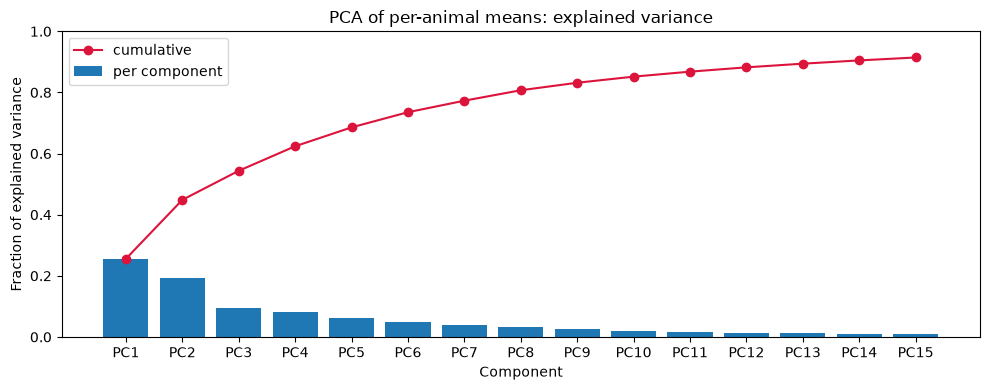

In [31]:
plot_explained_variance(mean_explained, "PCA of per-animal means: explained variance")

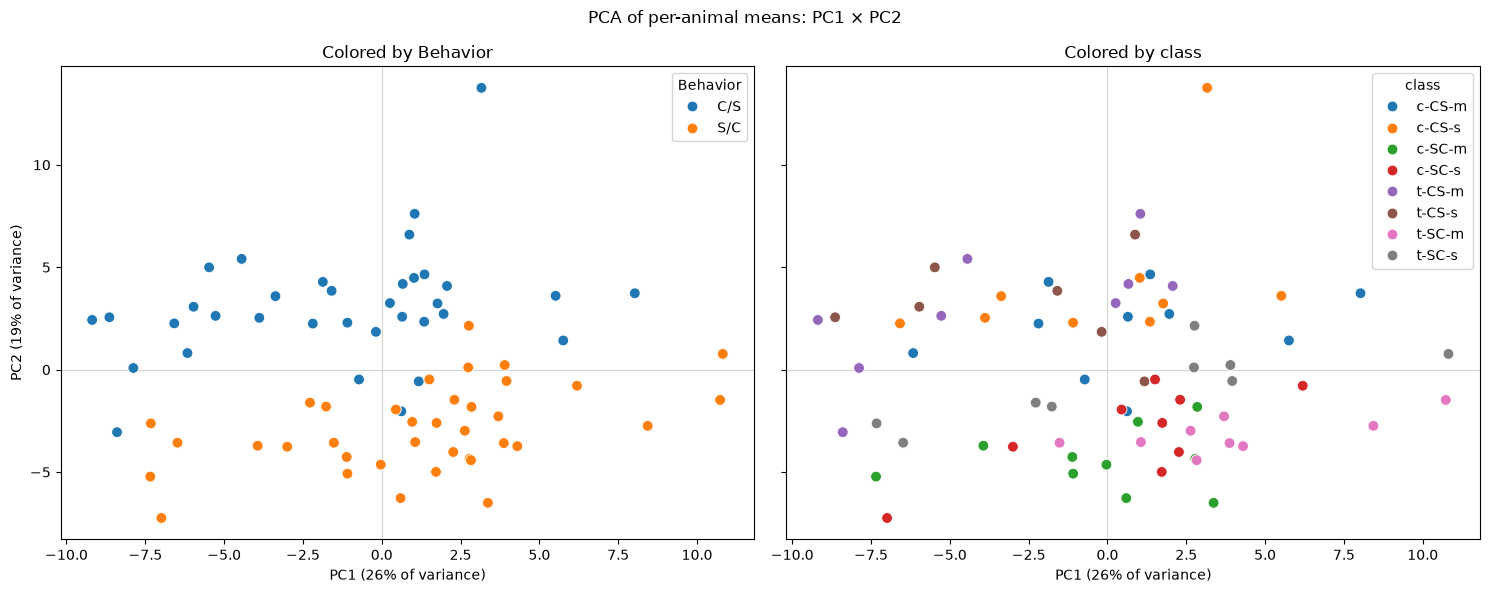

In [32]:
plot_pc1_pc2(mean_scores, mean_explained, "PCA of per-animal means: PC1 × PC2")

PC1 and PC2 summarize about 45% of the variance. CS and SC animals fall on opposite sides of PC2, although the PCA does not use the labels; the eight classes overlap in this plane.

In [33]:
pd.concat(
    {pc: top_loadings(mean_loadings, pc).reset_index().set_axis(["protein", "loading"], axis=1)
     for pc in ["PC1", "PC2"]},
    axis=1,
).round(3)

PC1               PC2        
    protein loading   protein loading
0  CAMKII_N   0.198   GSK3B_N   0.228
1     MEK_N   0.195    SNCA_N  -0.213
2    pMEK_N   0.190   ITSN1_N   0.207
3   pBRAF_N   0.189    CaNA_N   0.206
4    pJNK_N   0.187    pERK_N   0.200
5    pAKT_N   0.186    IL1B_N  -0.197
6     JNK_N   0.185  DYRK1A_N   0.196
7   pNR2B_N   0.182    BRAF_N   0.188
8    NR2B_N   0.182  pPKCAB_N   0.186
9    CREB_N   0.176     pS6_N  -0.182

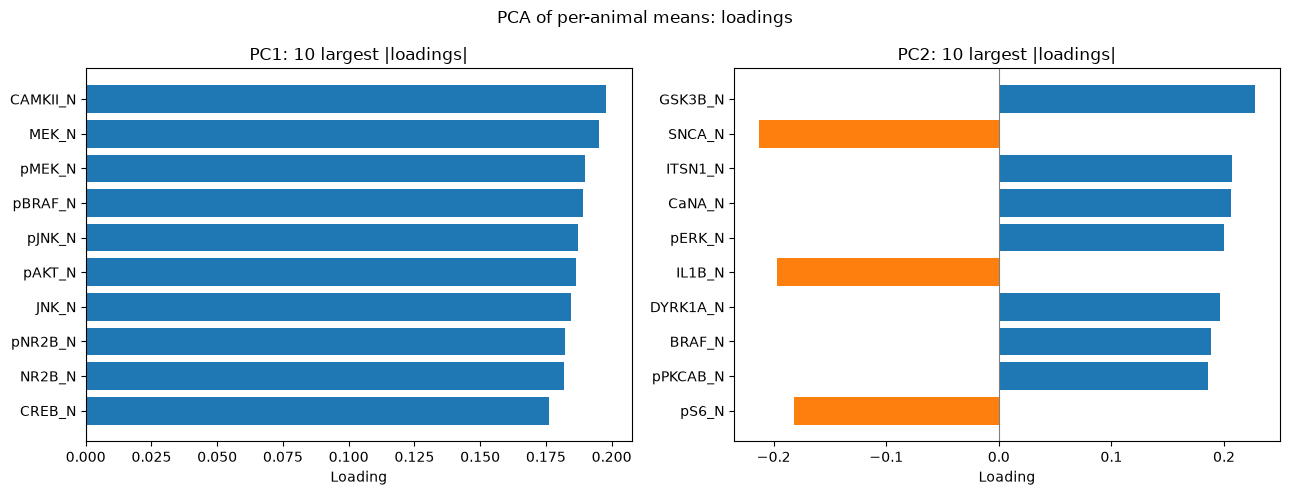

In [34]:
plot_top_loadings(mean_loadings, "PCA of per-animal means: loadings")

PC1 loadings are similar across many proteins (a shared overall-level component). The sign of a loading is arbitrary, and a large loading does not imply predictive power.

### **3.3 PCA of the per-animal standard deviations**

Same procedure with the 77 per-animal standard deviations, kept separate from the means.

In [35]:
std_scores, std_loadings, std_explained = fit_protein_pca(animal_std_df)

pd.DataFrame({
    "means": mean_explained.head(10),
    "stds": std_explained.head(10),
}).assign(**{
    "means (cum.)": lambda t: t["means"].cumsum(),
    "stds (cum.)": lambda t: t["stds"].cumsum(),
}).round(3)

,means,stds,means (cum.),stds (cum.)
PC1,0.256,0.225,0.256,0.225
PC2,0.193,0.127,0.449,0.352
PC3,0.095,0.097,0.544,0.449
PC4,0.080,0.061,0.624,0.510
PC5,0.062,0.049,0.686,0.559
PC6,0.050,0.044,0.735,0.603
PC7,0.038,0.037,0.773,0.640
PC8,0.034,0.030,0.807,0.669
PC9,0.025,0.029,0.832,0.698
PC10,0.020,0.027,0.852,0.725


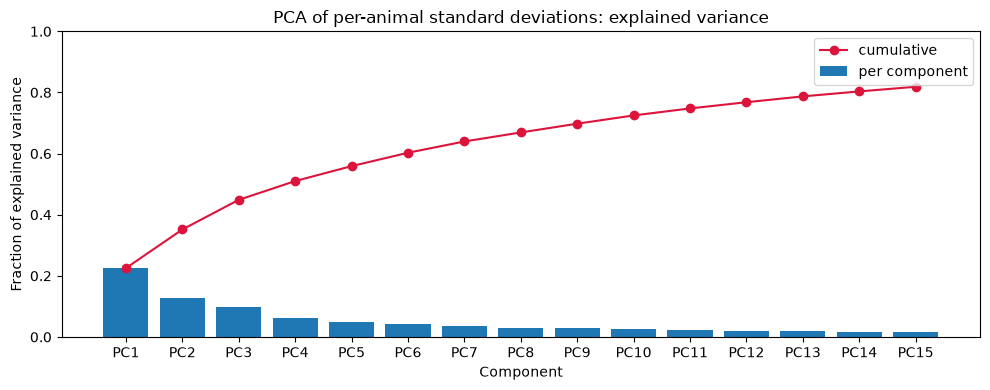

In [36]:
plot_explained_variance(std_explained, "PCA of per-animal standard deviations: explained variance")

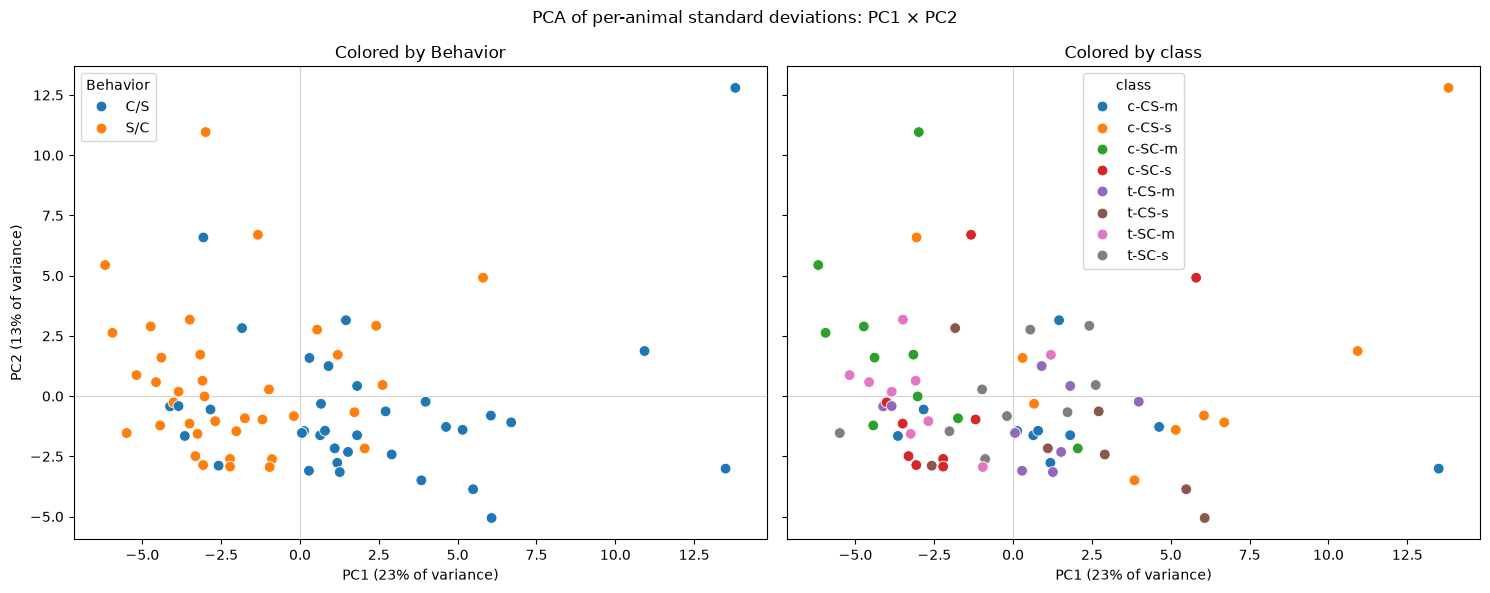

In [37]:
plot_pc1_pc2(std_scores, std_explained, "PCA of per-animal standard deviations: PC1 × PC2")

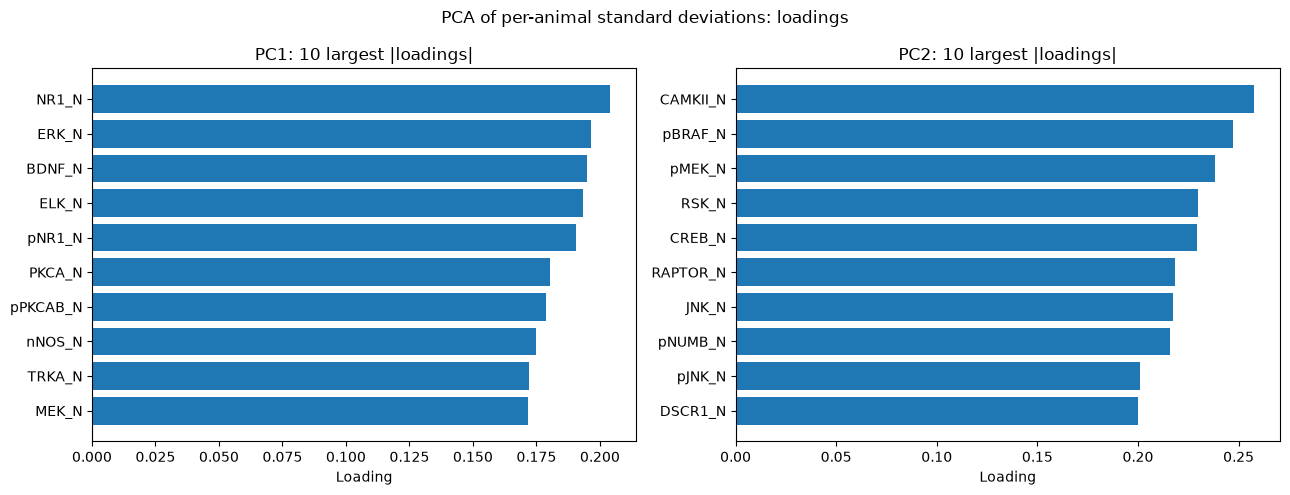

In [38]:
plot_top_loadings(std_loadings, "PCA of per-animal standard deviations: loadings")

The variance of the standard deviations is spread over more components, CS/SC appears along PC1 instead of PC2, and the cloud is less structured. Since the measurements include replicates and dilutions, the standard deviations are not treated as biological signal.

## **4. Box plots by class**

Each point is one animal; boxes summarize the 7 to 10 animals of each class.

In [39]:
class_order = sorted(animal_mean_df["class"].unique())


def plot_by_class(table, proteins, ylabel, title, ncols=4):
    nrows = -(-len(proteins) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.2 * nrows), squeeze=False)

    for ax, protein in zip(axes.flat, proteins):
        sns.boxplot(
            data=table, x="class", y=protein, order=class_order,
            showfliers=False, color="lightgray", ax=ax,
        )
        sns.stripplot(
            data=table, x="class", y=protein, order=class_order,
            color="tab:blue", alpha=0.7, jitter=0.18, ax=ax,
        )
        ax.set_title(protein)
        ax.set_xlabel("")
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=45)

    for ax in axes.flat[len(proteins):]:
        ax.set_visible(False)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### **4.1 Means: proteins with the largest loadings, plus SOD1_N**

The 3 proteins with the largest |loading| in PC1 and in PC2 of the PCA of the means, plus SOD1_N.

In [40]:
pca_proteins = list(dict.fromkeys(
    top_loadings(mean_loadings, "PC1", 3).index.tolist()
    + top_loadings(mean_loadings, "PC2", 3).index.tolist()
    + ["SOD1_N"]
))

ratio_proteins = (
    variability_summary
    .nsmallest(4, "within_between_ratio")["protein"]
    .tolist()
)

print(f"From loadings (+ SOD1_N): {pca_proteins}")
print(f"Lowest within/between ratio: {ratio_proteins}")

From loadings (+ SOD1_N): ['CAMKII_N', 'MEK_N', 'pMEK_N', 'GSK3B_N', 'SNCA_N', 'ITSN1_N', 'SOD1_N']
Lowest within/between ratio: ['AcetylH3K9_N', 'BRAF_N', 'pPKCG_N', 'SOD1_N']


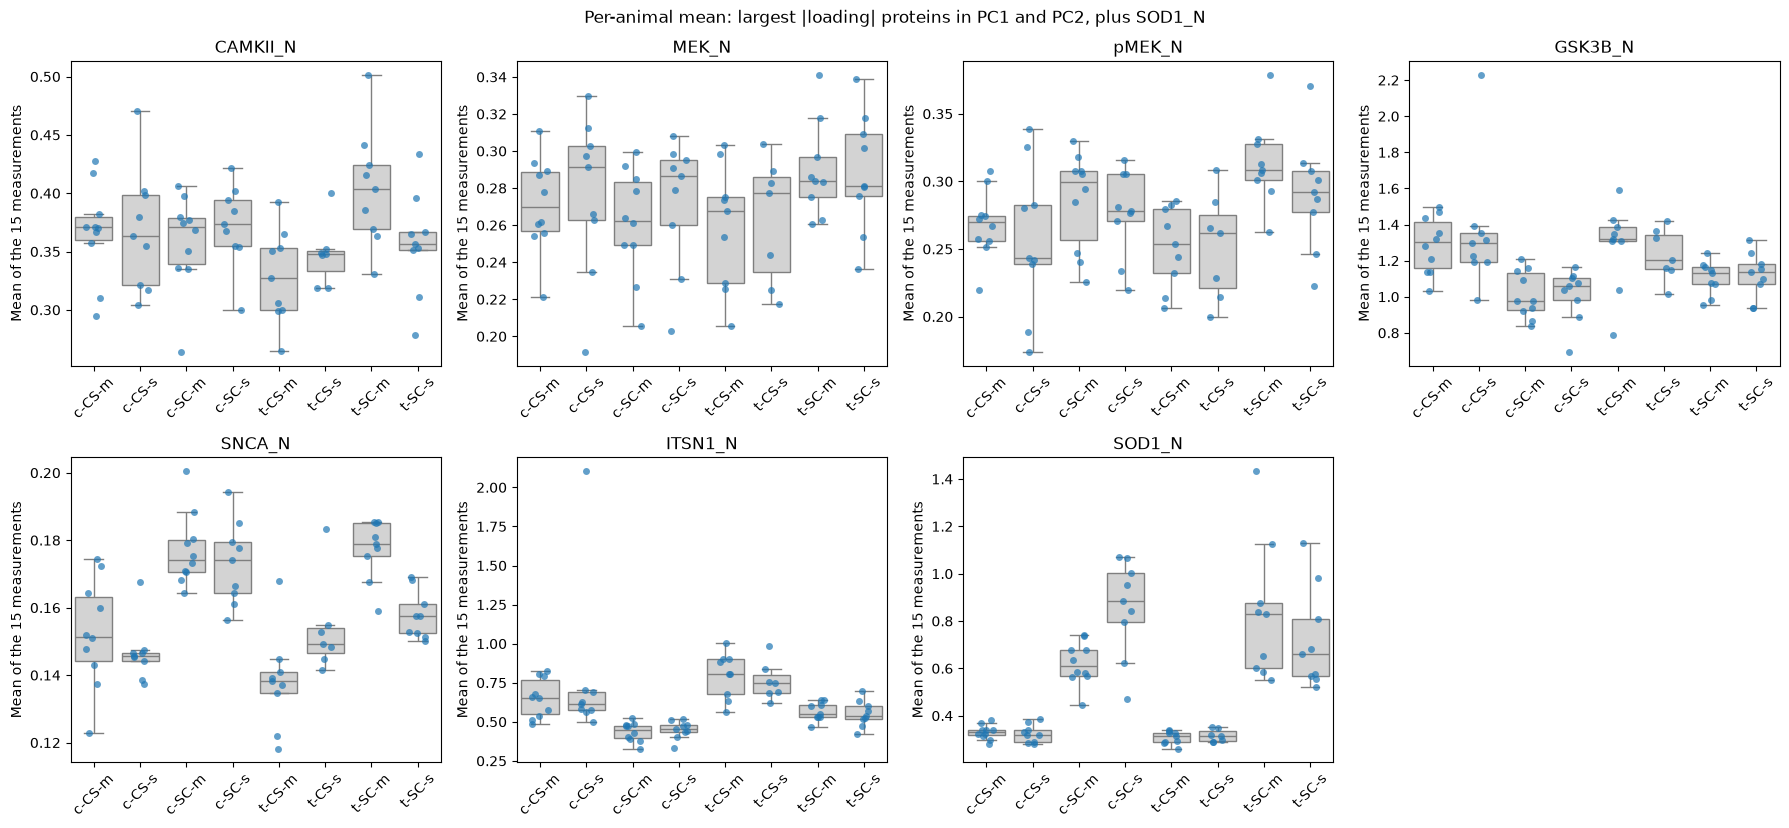

In [41]:
plot_by_class(
    animal_mean_df, pca_proteins,
    ylabel="Mean of the 15 measurements",
    title="Per-animal mean: largest |loading| proteins in PC1 and PC2, plus SOD1_N",
)

SOD1_N clearly separates CS (low) from SC (high). PC2 proteins (GSK3B_N, SNCA_N, ITSN1_N) also follow CS/SC with more overlap; PC1 proteins (CAMKII_N, MEK_N, pMEK_N) barely differ between classes.

### **4.2 Means: the four proteins with the lowest within/between ratio**

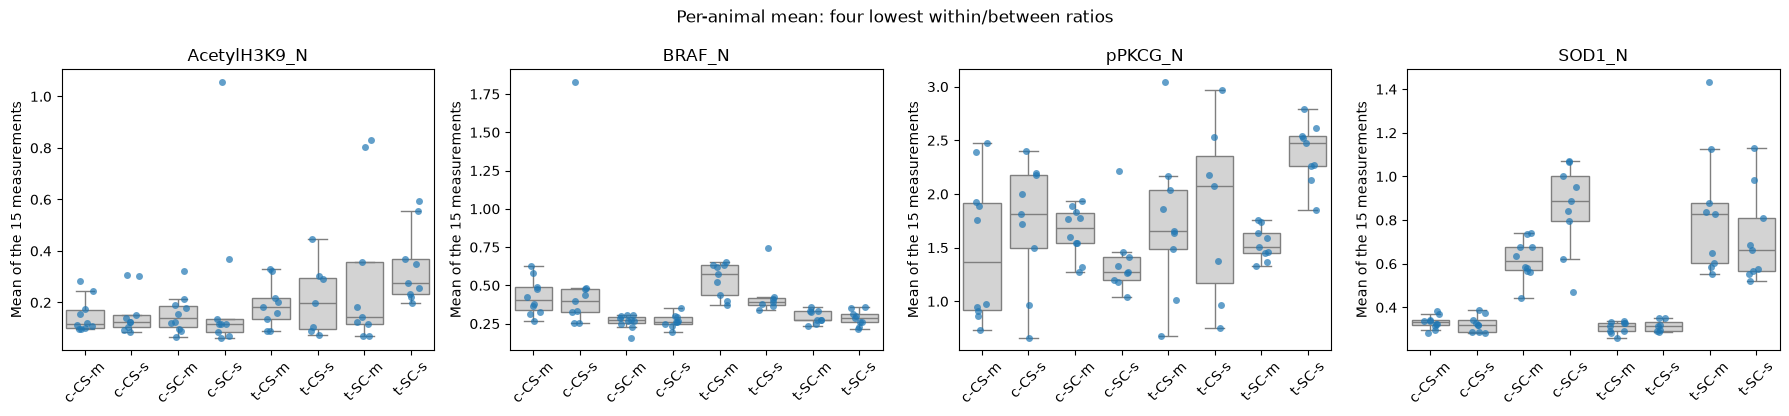

In [42]:
plot_by_class(
    animal_mean_df, ratio_proteins,
    ylabel="Mean of the 15 measurements",
    title="Per-animal mean: four lowest within/between ratios",
)

A low ratio does not imply class separation: SOD1_N separates CS/SC and BRAF_N highlights t-CS-m, but AcetylH3K9_N and pPKCG_N overlap across classes.

Detail of AcetylH3K9_N in t-CS-s: mean per animal.

In [43]:
df[["animal_id", "class", "AcetylH3K9_N"]][df["class"] == "t-CS-s"].groupby(["class", "animal_id"]).agg(n_mices_per_class=("animal_id", "nunique"), mean_v=("AcetylH3K9_N", "mean"))

n_mices_per_class    mean_v
class  animal_id                             
t-CS-s 18899                      1  0.199274
       3476                       1  0.300985
       3483                       1  0.447671
       3498                       1  0.090590
       50810B                     1  0.073991
       50810C                     1  0.103874
       50810E                     1  0.290659

## **5. Trisomic mice: PCA and K-means**

PCA of the per-animal means and K-means restricted to the 34 Ts65Dn animals. Saringat et al. (2018, https://doi.org/10.30880/ijie.2018.10.06.004) run K-means with \(k=2\) on measurement instances; here each point is an animal, so the question is different: do the mean profiles of trisomic animals group naturally by behavior or by class?

Labels (Behavior and class) are used only for evaluation (cluster × label tables and ARI), never to fit the imputation, scaling, PCA or K-means.

### **5.1 Per-animal means of the trisomic mice**

In [44]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

trisomic_mean_df = animal_mean_df[animal_mean_df["Genotype"] == "Ts65Dn"].reset_index(drop=True)

assert len(trisomic_mean_df) == 34
assert trisomic_mean_df["class"].str.startswith("t-").all()

trisomic_mean_df["class"].value_counts().sort_index().rename("animals").to_frame().T

class,t-CS-m,t-CS-s,t-SC-m,t-SC-s
animals,9,7,9,9


### **5.2 PCA of the trisomic means**

In [45]:
trisomic_scores, trisomic_loadings, trisomic_explained = fit_protein_pca(trisomic_mean_df)

trisomic_explained.head(5).to_frame("explained").assign(cumulative=lambda t: t["explained"].cumsum()).round(3)

,explained,cumulative
PC1,0.346,0.346
PC2,0.176,0.522
PC3,0.095,0.617
PC4,0.080,0.697
PC5,0.049,0.746


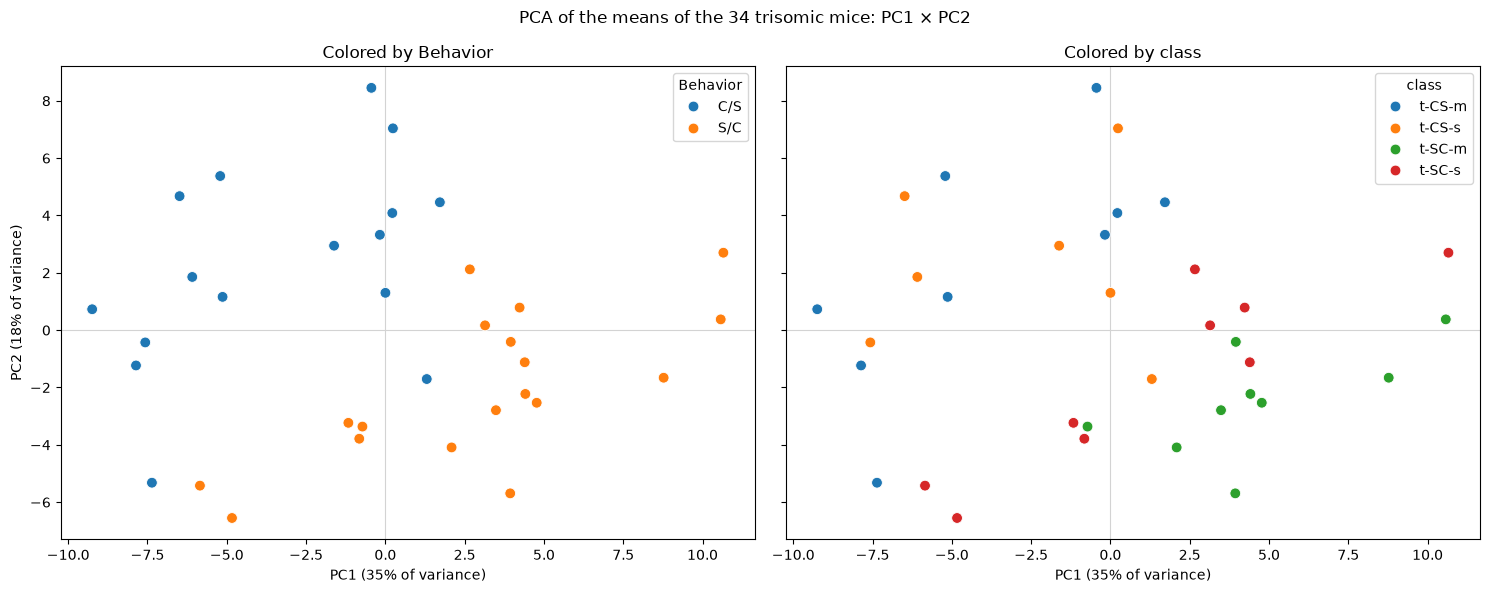

In [46]:
plot_pc1_pc2(trisomic_scores, trisomic_explained, "PCA of the means of the 34 trisomic mice: PC1 × PC2")

PC1 and PC2 summarize about 52% of the variance. CS and SC occupy different regions, separated along a diagonal, with a few animals on the opposite side; within each behavior, memantine and saline mix.

### **5.3 K-means with \(k=2\) and \(k=4\)**

Two input spaces, both fitted on the 34 animals without labels: the 77 standardized proteins (median imputation + standardization) and PC1–PC2 of section 5.2. K-means uses `n_init=50` and `random_state=42`. Cluster numbers are arbitrary. The ARI is 1 when clusters reproduce the labels and close to 0 for chance-level agreement.

In [47]:
standardized_proteins = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler()
).fit_transform(trisomic_mean_df[protein_cols])

clustering_spaces = {
    "77 standardized proteins": standardized_proteins,
    "PC1 and PC2": trisomic_scores[["PC1", "PC2"]].to_numpy(),
}
kmeans_targets = {2: "Behavior", 4: "class"}

kmeans_clusters = {
    (space, k): pd.Series(
        KMeans(n_clusters=k, n_init=50, random_state=42).fit_predict(values), name="cluster"
    )
    for space, values in clustering_spaces.items()
    for k in kmeans_targets
}


def cluster_crosstab(k):
    target = kmeans_targets[k]
    return pd.concat(
        {space: pd.crosstab(kmeans_clusters[(space, k)], trisomic_mean_df[target])
         for space in clustering_spaces},
        axis=1,
    )

**\(k=2\): cluster × Behavior (CS/SC)**

In [48]:
cluster_crosstab(2)

77 standardized proteins     PC1 and PC2    
Behavior                      C/S S/C         C/S S/C
cluster                                              
0                               8  15           8   2
1                               8   3           8  16

**\(k=4\): cluster × class**

In [49]:
cluster_crosstab(4)

77 standardized proteins                      PC1 and PC2         \
class                     t-CS-m t-CS-s t-SC-m t-SC-s      t-CS-m t-CS-s   
cluster                                                                    
0                              4      2      0      0           0      1   
1                              0      1      8      4           4      2   
2                              1      1      1      4           5      4   
3                              4      3      0      1           0      0   

                       
class   t-SC-m t-SC-s  
cluster                
0            7      6  
1            0      2  
2            0      0  
3            2      1

**ARI of each combination**

In [50]:
ari_table = pd.DataFrame(
    [
        {"space": space, "k": k, "compared with": kmeans_targets[k],
         "ARI": adjusted_rand_score(trisomic_mean_df[kmeans_targets[k]], clusters)}
        for (space, k), clusters in kmeans_clusters.items()
    ]
).round(3)
ari_table

,space,k,compared with,ARI
0,77 standardized proteins,2,Behavior,0.100
1,77 standardized proteins,4,class,0.227
2,PC1 and PC2,2,Behavior,0.148
3,PC1 and PC2,4,class,0.230


- \(k=2\) does not recover CS/SC: in both spaces the 16 CS animals split 8/8 between clusters (ARI 0.10 and 0.15).
- \(k=4\) reaches an ARI of about 0.23: one cluster is mostly SC, while CS animals spread over the others without separating memantine from saline.

Per animal, the four trisomic classes do not appear as natural clusters; the hard part is distinguishing memantine from saline.